# 🧪 LAB: Implement an autoencoder with `PyTorch`

In this lab, you will implement and explore autoencoders using the MNIST dataset. The goal is to understand how autoencoders learn compressed representations of data, and how these representations compare with classical methods like PCA.

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


NAME(s) = "Shreyans Jain, Luke Hakso, Thomas Gao"

## 1. Theoretical Background Reflection (10 points)

Read *Michelucci (2022)*: [An Introduction to Autoencoders](https://arxiv.org/abs/2201.03898) — focus on the following sections:  
- 1. Introduction
- 2.1, 2.2, and 2.3
- Skim Section 3 on applications  

Then answer briefly:

1. What is the main idea behind an autoencoder?  
Take the original input to reconstruct it with the lowest error possible.  It's primary purpose is to learn an informative representation of the data that can be used for different applications by learning to reconstruct a set of input observations well enough.
2. What is the role of the bottleneck layer?  
To force the model to learn salient features/reduce dimensionality of the latent representation.  

3. Discuss, in your own words, the applications of autoencoders mentioned in the paper.  
Anomaly detection, classification with latent features, and dimensionality reduction.  

4. What differences would you expect between an autoencoder’s representation and that of PCA if applied as a dimensionality reduction technique?  

The autoencoder can represent nonlinear functions more effectively, so its low-dimensional representation can contain more complex patterns.


USE AS MANY MARKDOWN CELLS AS NEEDED

## 2. Prepare the Data (10 points)

Given the below dataset:

- Normalize **each** image (i.e., separately) so its values are between 0 and 1. Remember our first-week discussions of fixed and fitted transformations.
- Visualize a few random digits to confirm everything worked as expected.
- Split the dataset into fitting, tuning and reporting sets (70%, 15%, 15%).
- Wrap each data splitting as `DataLoader` object with a batch size of 128. Call them `fitting_loader`, `tuning_loader` and `reporting_loader`, respectively.

In [1]:
from sklearn.datasets import fetch_openml
mnist = fetch_openml("mnist_784", version=1, as_frame=False, n_retries=5, delay=2)
X, y = mnist.data, mnist.target.astype(int)

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split

# min-max scale each image (row) separately with its own min and max
X_min = X.min(axis=1, keepdims=True)
X_max = X.max(axis=1, keepdims=True)
X_norm = (X - X_min) / (X_max - X_min)

print(f"Shape: {X_norm.shape}")
print(f"Every image has min 0: {np.allclose(X_norm.min(axis=1), 0)}")
print(f"Every image has max 1: {np.allclose(X_norm.max(axis=1), 1)}")

Shape: (70000, 784)
Every image has min 0: True
Every image has max 1: True


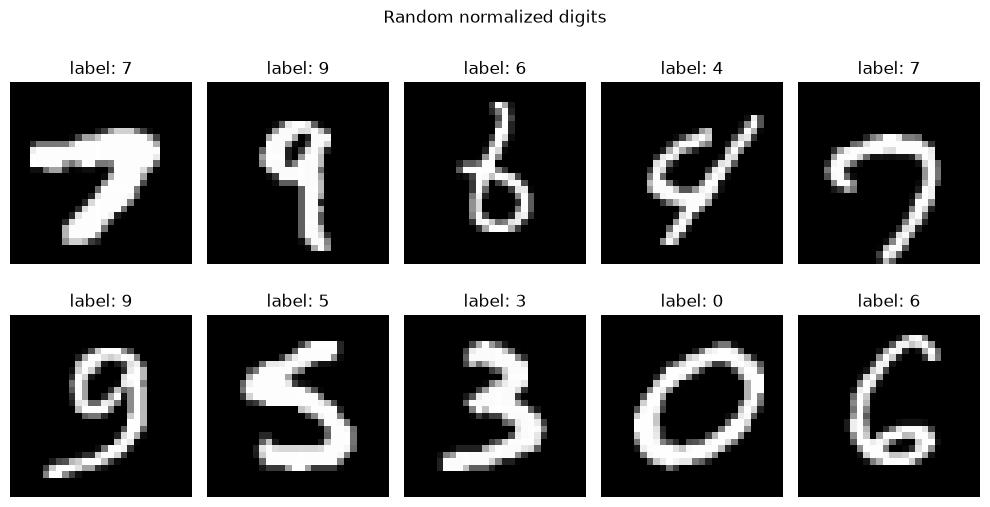

In [3]:
# make sure normalization didn't ruin images
rng = np.random.default_rng(42)
idx = rng.choice(len(X_norm), size=10, replace=False) #choose random idxs for which images to show

fig, axes = plt.subplots(2, 5, figsize=(10, 5.5))
for ax, i in zip(axes.ravel(), idx):
    ax.imshow(X_norm[i].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"label: {y[i]}")
    ax.axis("off")
fig.suptitle("Random normalized digits")
plt.tight_layout()
plt.show()

In [4]:
# 70% fitting, then split the remaining 30% in half for tuning and reporting.
# stratify keeps the digit proportions the same in every set
X_fit, X_rest, y_fit, y_rest = train_test_split(X_norm, y, test_size=0.30, stratify=y, random_state=42)
X_tune, X_report, y_tune, y_report = train_test_split(X_rest, y_rest, test_size=0.50, stratify=y_rest, random_state=42)

for name, part in [("fitting", X_fit), ("tuning", X_tune), ("reporting", X_report)]:
    print(f"{name}: {len(part)} images ({len(part) / len(X_norm):.0%})")

fitting: 49000 images (70%)
tuning: 10500 images (15%)
reporting: 10500 images (15%)


In [5]:
BATCH_SIZE = 128

def make_loader(X, y, shuffle):
    dataset = TensorDataset(torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.long))
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle)

torch.manual_seed(42)
# only the fitting set is shuffled; the order of the other two doesn't affect evaluation
fitting_loader = make_loader(X_fit, y_fit, shuffle=True)
tuning_loader = make_loader(X_tune, y_tune, shuffle=False)
reporting_loader = make_loader(X_report, y_report, shuffle=False)

X_batch, y_batch = next(iter(fitting_loader)) #get the first batch from the fitting loader
print(f"Batch shapes: X {tuple(X_batch.shape)}, y {tuple(y_batch.shape)}")
print(f"Batches per set: {len(fitting_loader)}, {len(tuning_loader)}, {len(reporting_loader)}")

Batch shapes: X (128, 784), y (128,)
Batches per set: 383, 83, 83


## 3. Autoencoder

In this section, you will build and train an **autoencoder** to reconstruct the provided data.

Your model will include three layers in both the encoder and decoder:

- **Encoder:** 784 → 128 → 64 → 2. This last layer here is the **bottleneck**.
- **Decoder:** 2 → 64 → 128 → 784  

### 3.1 Implementation (30 points)

Follow the skeleton provided below and fill in the missing parts (`#TODO`). 

Follow these restrictions:

- Each **hidden** layer should include a linear transformation, ReLU activation function, dropout with `p=0.2` and batch normalization steps. Determine the appropriate order for these components based on what we discussed in class. The bottleneck layer is the exception; see next point.
- For the bottleneck, use only a linear transformation, i.e., no activation, batch normalization, or dropout.
- The output layer should have a sigmoid activation function.

In [6]:
import torch.nn as nn

class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        
        # ENCODING PART: 784 -> 128 -> 64 -> 2
        encoder_list = [
            # 784 -> 128
            nn.Linear(784, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(p=0.2),
            # 128 -> 64
            nn.Linear(128, 64), nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(p=0.2),
            # 64 -> 2, the bottleneck is only a linear transformation
            nn.Linear(64, 2),
        ]
        # ModuleList registers every layer as a submodule so its parameters get trained,
        # but unlike Sequential it leaves the iteration to us in forward
        self.encoder_list = nn.ModuleList(encoder_list)
        
        # DECODING PART: 2 -> 64 -> 128 -> 784
        decoder_list = [
            # 2 -> 64
            nn.Linear(2, 64), nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(p=0.2),
            # 64 -> 128
            nn.Linear(64, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(p=0.2),
            # 128 -> 784, sigmoid keeps every reconstructed pixel between 0 and 1
            nn.Linear(128, 784), nn.Sigmoid(),
        ]
        self.decoder_list = nn.ModuleList(decoder_list)

    def encode(self, X):
        for layer in self.encoder_list:
            X = layer(X)
        return X

    def decode(self, Z):
        for layer in self.decoder_list:
            Z = layer(Z)
        return Z
        
    def forward(self, X):
        # X -> encoder -> 2d latent code -> decoder -> reconstruction
        output = self.decode(self.encode(X))
        return output

**Order of the steps in each hidden layer.**

Every hidden layer goes linear, then batch normalization, then ReLU, then dropout. Batch normalization comes straight after the linear step so it standardizes the pre activations, which is where the original batch norm paper puts it, and the ReLU then works on values that are centred and on a stable scale. Dropout goes last so it only zeroes finished activations. If dropout came before batch normalization, the batch statistics would be computed on randomly zeroed values during training but on full values in eval mode, so the running mean and variance would not match what the layer actually sees at evaluation time. The bottleneck is a plain linear layer so the two latent coordinates can take any real value, and the output layer is linear followed by a sigmoid.

### 3.2 Training (15 points)

Follow the skeleton provided below and fill in the missing parts to train your model (`#TODO`). As you can see, training includes EarlyStopping, which I give you already for your convenience :-). After you have filled these missing parts, uncomment the provided piece of code with the function for training (`train_autoencoder`) your model and execute it.

But, **BEFORE** that, discuss with your mates and provide elaborated answers to the following:

- Why do you think the output layer of the autoencoder above uses a Sigmoid activation?
- Based on this, which cost function is most appropriate for this task? Justify your choice.

**Why the output layer uses a sigmoid.**

Every input pixel was scaled to lie between 0 and 1, and the decoder is trying to hand those same values back. A sigmoid squashes any number into the range between 0 and 1, so a reconstructed pixel can never land outside the range the real pixels live in. Without it the last linear layer could output negative values or values above 1, and part of the training would go into learning not to do that. It also lets each output be read as how strongly that pixel is switched on, which suits MNIST well because most pixels are close to 0 or close to 1 after normalization.

**Which cost function is most appropriate.**

We use binary cross entropy, `nn.BCELoss`. It expects predictions between 0 and 1, which is exactly what the sigmoid produces, and the targets do not have to be exactly 0 or 1, so the normalized pixels work as soft targets. For each pixel BCE is smallest when the output equals the target, so it rewards faithful reconstruction just like MSE does.

The main reason to prefer it is the gradient. With a sigmoid output and BCE, the gradient with respect to the pre activation is simply the output minus the target, so a pixel that is badly wrong, for example predicted near 0 when it should be 1, still gets a strong push. With MSE that same gradient gets multiplied by the slope of the sigmoid, which is almost zero once the sigmoid saturates, so the worst pixels end up learning the slowest. MSE would still be a defensible choice because the pixels are continuous, but we expect BCE to train faster and give sharper digits. One thing to keep in mind is that BCE does not reach zero when targets fall between 0 and 1, so the cost has a floor above zero. We therefore compare costs across epochs and splits instead of reading the value on its own, and we also report MSE for the reconstructions.

Once you have discussed and agreed on the reasoning above, proceed to complete the skeleton (`#TODO`) and train the model.


In [7]:
torch.manual_seed(42)  # same starting weights every time the notebook is run

model = Autoencoder()

# sigmoid outputs and targets are both in [0,1], so binary cross entropy fits (see discussion above)
criterion = nn.BCELoss()

# Adam with lr 0.001 and L2 regularization through weight_decay
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-5)
print(model)

Autoencoder(
  (encoder_list): ModuleList(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=64, out_features=2, bias=True)
  )
  (decoder_list): ModuleList(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=64, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)

In [8]:
class EarlyStopping:
    def __init__(self, patience=10, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = None
        self.early_stop = False
        self.best_model_state = None

    def __call__(self, tuning_loss, model):
        if self.best_loss is None or tuning_loss < self.best_loss - self.min_delta:
            self.best_loss = tuning_loss
            self.counter = 0
            self.best_model_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True

    def restore_best_weights(self, model):
        if self.best_model_state is not None:
            model.load_state_dict(self.best_model_state)


def train_autoencoder(model, fitting_loader, tuning_loader, n_epochs=100, patience=5):
    # Initialize the early stopping object
    early_stopping = EarlyStopping(patience=patience)
    history = {"fitting": [], "tuning": []}

    for epoch in range(n_epochs):
        model.train()
        fitting_cost = 0.0

        for X_batch, _ in fitting_loader:
            # --- Implement the standard training steps ---
            
            outputs = model(X_batch)             # forward pass, the reconstruction of the batch
            cost = criterion(outputs, X_batch)   # the target is the input itself
            cost.backward()                      # backward pass, compute gradients
            optimizer.step()                     # update model parameters
            optimizer.zero_grad()                # reset gradients for the next batch
            fitting_cost += cost.item() * X_batch.size(0)

        fitting_cost /= len(fitting_loader.dataset)

        # --- Tuning phase ---
        model.eval()
        tuning_cost = 0.0
        with torch.no_grad():
            for X_batch, _ in tuning_loader:
                outputs = model(X_batch)
                cost = criterion(outputs, X_batch)
                tuning_cost += cost.item() * X_batch.size(0)

        tuning_cost /= len(tuning_loader.dataset)

        # --- Save metrics ---
        history["fitting"].append(fitting_cost)
        history["tuning"].append(tuning_cost)

        print(f"Epoch [{epoch+1}/{n_epochs}]  Fitting Cost: {fitting_cost:.5f}  Tuning Cost: {tuning_cost:.5f}")

        # --- Early stopping check ---
        early_stopping(tuning_cost, model)
        if early_stopping.early_stop:
            print(f"Stopping early at epoch {epoch+1}")
            early_stopping.restore_best_weights(model)
            return model, history

    return model, history

Once the missing parts have been filled, uncomment the piece of code below and execute it to train your model (it may take a bit to complete the training, which is totally normal).

In [9]:
model, history = train_autoencoder(model, fitting_loader, tuning_loader, n_epochs=50, patience=5)

Epoch [1/50]  Fitting Cost: 0.25903  Tuning Cost: 0.21085


Epoch [2/50]  Fitting Cost: 0.21283  Tuning Cost: 0.20320


Epoch [3/50]  Fitting Cost: 0.20874  Tuning Cost: 0.20038


Epoch [4/50]  Fitting Cost: 0.20675  Tuning Cost: 0.19851


Epoch [5/50]  Fitting Cost: 0.20559  Tuning Cost: 0.19729


Epoch [6/50]  Fitting Cost: 0.20454  Tuning Cost: 0.19655


... (40 outputs left out)

Epoch [47/50]  Fitting Cost: 0.19752  Tuning Cost: 0.18782


Epoch [48/50]  Fitting Cost: 0.19742  Tuning Cost: 0.18761


Epoch [49/50]  Fitting Cost: 0.19741  Tuning Cost: 0.18735


Epoch [50/50]  Fitting Cost: 0.19729  Tuning Cost: 0.18733


Epochs run: 50
Best tuning cost: 0.18733 at epoch 50 (these weights were restored)


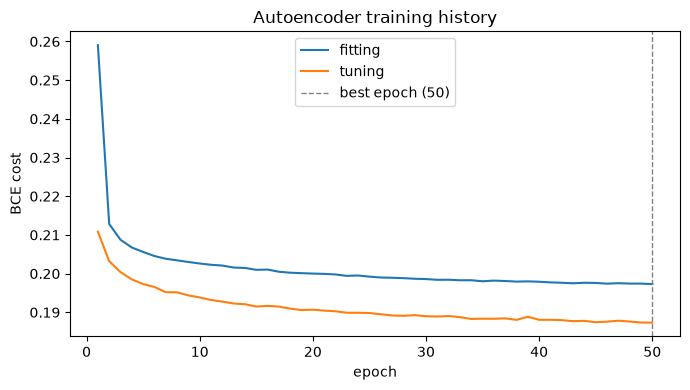

In [10]:
best_epoch = int(np.argmin(history["tuning"])) + 1
print(f"Epochs run: {len(history['tuning'])}")
print(f"Best tuning cost: {min(history['tuning']):.5f} at epoch {best_epoch} (these weights were restored)")

epochs = np.arange(1, len(history["fitting"]) + 1)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(epochs, history["fitting"], label="fitting")
ax.plot(epochs, history["tuning"], label="tuning")
ax.axvline(best_epoch, color="gray", linestyle="--", linewidth=1, label=f"best epoch ({best_epoch})")
ax.set_xlabel("epoch")
ax.set_ylabel("BCE cost")
ax.set_title("Autoencoder training history")
ax.legend()
plt.tight_layout()
plt.show()

**Training.**

The fitting cost is computed with dropout switched on while the tuning cost uses the full network in eval mode, so the tuning curve can sit at or below the fitting curve without that meaning anything is wrong. What matters for early stopping is when the tuning cost stops improving, and the weights from that best epoch are the ones used in every section below.

### 3.3 Reconstruct (5 points)

Once you have trained the model: 

1. Visualize several reconstructed digits from the reporting set.  
2. Compare them with the corresponding original input digits. Was the reconstruction good? 

In [11]:
# reconstruct the whole reporting set once with the trained model in eval mode
model.eval()
X_report_t = torch.tensor(X_report, dtype=torch.float32)
with torch.no_grad():
    recon_report = model(X_report_t).numpy()

report_bce = criterion(torch.tensor(recon_report), X_report_t).item()
mse_per_image = ((recon_report - X_report) ** 2).mean(axis=1)
print(f"Reporting set BCE cost: {report_bce:.5f}")
print(f"Reporting set MSE per pixel: {mse_per_image.mean():.5f}")
print("\nMean MSE by digit")
for d in range(10):
    print(f"  {d}: {mse_per_image[y_report == d].mean():.5f}")

Reporting set BCE cost: 0.18683
Reporting set MSE per pixel: 0.04181

Mean MSE by digit
  0: 0.04558
  1: 0.01433
  2: 0.05646
  3: 0.04988
  4: 0.04268
  5: 0.05044
  6: 0.04022
  7: 0.03658
  8: 0.04987
  9: 0.03665


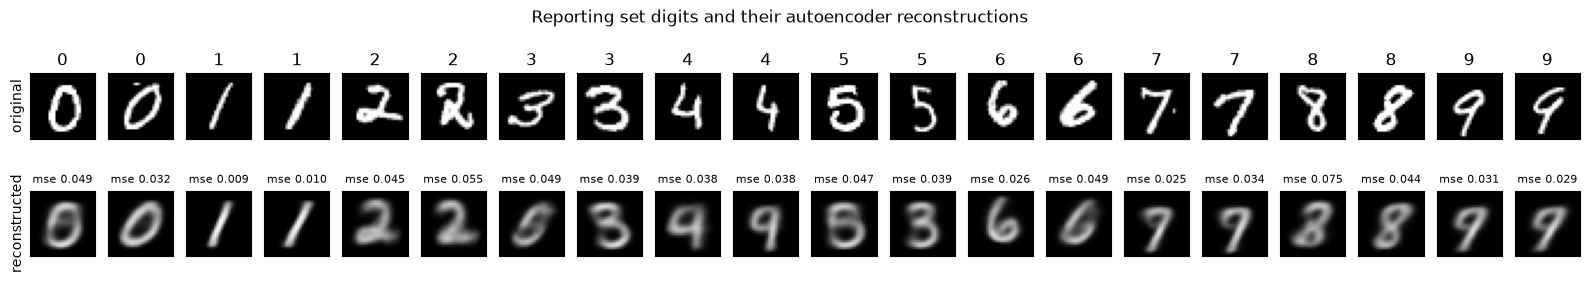

In [12]:
# two random reporting images per digit, originals on top and reconstructions below
rng = np.random.default_rng(7)
show_idx = np.concatenate([rng.choice(np.where(y_report == d)[0], size=2, replace=False) for d in range(10)])

fig, axes = plt.subplots(2, len(show_idx), figsize=(20, 2.8))
for col, i in enumerate(show_idx):
    for row, img in enumerate([X_report[i], recon_report[i]]):
        ax = axes[row, col]
        ax.imshow(img.reshape(28, 28), cmap="gray", vmin=0, vmax=1)
        ax.set_xticks([]); ax.set_yticks([])
    axes[0, col].set_title(f"{y_report[i]}")
    axes[1, col].set_title(f"mse {mse_per_image[i]:.3f}", fontsize=8)
axes[0, 0].set_ylabel("original")
axes[1, 0].set_ylabel("reconstructed")
fig.suptitle("Reporting set digits and their autoencoder reconstructions", y=1.05)
plt.show()

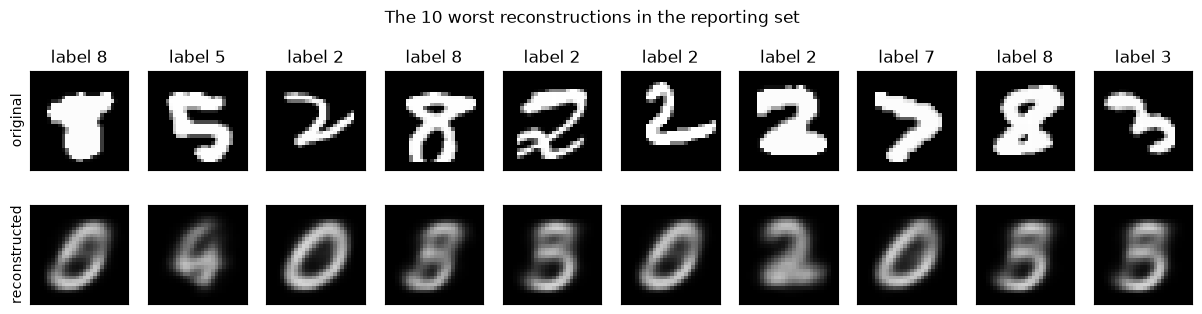

In [13]:
# the worst reconstructions show where two numbers are not enough
worst = np.argsort(mse_per_image)[-10:][::-1]
fig, axes = plt.subplots(2, 10, figsize=(15, 3.2))
for col, i in enumerate(worst):
    for row, img in enumerate([X_report[i], recon_report[i]]):
        axes[row, col].imshow(img.reshape(28, 28), cmap="gray", vmin=0, vmax=1)
        axes[row, col].set_xticks([]); axes[row, col].set_yticks([])
    axes[0, col].set_title(f"label {y_report[i]}")
axes[0, 0].set_ylabel("original")
axes[1, 0].set_ylabel("reconstructed")
fig.suptitle("The 10 worst reconstructions in the reporting set", y=1.05)
plt.show()

**Was the reconstruction good?**

It is good for how little room the model has, but it is not a faithful copy. Every image is squeezed into just two numbers, so the decoder can only produce something close to a typical version of a digit. The reconstructions keep the overall shape and position of the strokes, and most of them can be read as the right digit, but they come out blurry and lose the details that make each handwritten digit unique, such as slant, stroke thickness, small loops and extra strokes. Simple, consistent shapes like 1 and 0 come back best, which the per digit errors above reflect. Digits that share a lot of strokes, such as 4 and 9 or 3, 5 and 8, are where the decoder most often draws a mix of the two or even the wrong digit, and the worst reconstructions are mostly unusual handwriting that does not look like the typical version of its class. A wider bottleneck would sharpen the reconstructions, but two dimensions is what lets us plot the latent space directly in the next section.

## 4. Visualize the Learned Representations (15 points)

Here you will explore the latent representations learned by your autoencoder.

1. Complete `extract_latent_features` to extract the latent (bottleneck) features and their corresponding labels, given a trained model.  
   Apply this function to the reporting set using the provided code. This should give you the transformed reporting set with the dimensions of the bottleneck (2).
2. Plot the reduced 2D data as a scatterplot, coloring each point by its corresponding digit label.


In [14]:
def extract_latent_features(model, dataloader): 
    model.eval()
    latents = []
    labels = []

    with torch.no_grad():
        for X_batch, y_batch in dataloader:
            
            encoded = model.encode(X_batch)  # only the encoder half, giving the 2d bottleneck features
            latents.append(encoded.numpy())
            labels.append(y_batch.numpy())

    # Concatenate all batches
    latents = np.concatenate(latents, axis=0)
    labels = np.concatenate(labels, axis=0)
    return latents, labels

Once the missing parts above have been filled, uncomment the piece of code below and execute it to extract the latent features

In [15]:
latents_autoencoder, labels = extract_latent_features(model, reporting_loader)
print(f"Latent features: {latents_autoencoder.shape}, labels: {labels.shape}")

Latent features: (10500, 2), labels: (10500,)


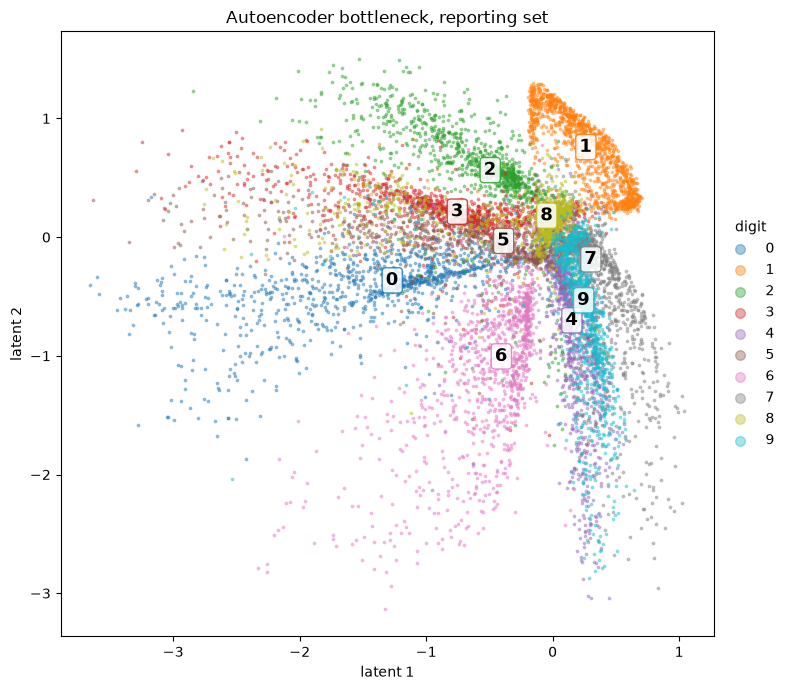

In [16]:
def plot_2d(Z, labels, title, ax, axis_names=("dimension 1", "dimension 2")):
    cmap = plt.get_cmap("tab10")
    for d in range(10):
        mask = labels == d
        ax.scatter(Z[mask, 0], Z[mask, 1], s=3, alpha=0.4, color=cmap(d), label=str(d), rasterized=True)
    # write each digit at the median of its points so the clusters are easy to read
    for d in range(10):
        cx, cy = np.median(Z[labels == d], axis=0)
        ax.text(cx, cy, str(d), fontsize=13, weight="bold", ha="center", va="center",
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec=cmap(d), alpha=0.85))
    ax.set_title(title)
    ax.set_xlabel(axis_names[0])
    ax.set_ylabel(axis_names[1])
    ax.legend(title="digit", markerscale=4, loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False)

fig, ax = plt.subplots(figsize=(8, 7))
plot_2d(latents_autoencoder, labels, "Autoencoder bottleneck, reporting set", ax, ("latent 1", "latent 2"))
plt.tight_layout()
plt.show()

**What the latent space shows.**

Even though the model was never shown a label, the points of each digit gather in their own region of the 2d plane, so the autoencoder organized the space by digit identity as a side effect of learning to reconstruct. Digits with distinctive shapes, such as 0, 1, 2 and 6, form the clearest groups, while digits that look alike sit next to each other and partly overlap, especially 4, 7 and 9 and the group of 3, 5 and 8. This matches the reconstruction results, since digits that share a region of the latent space are exactly the ones the decoder tends to confuse. The two axes themselves have no fixed meaning, and a different random seed would give a rotated or rearranged map with the same neighbourhoods.

## 5. Compare with PCA (10 points)

Here you will compare the latent representations learned by your autoencoder with those obtained using a PCA.

1. Apply a PCA to the reporting set (without using the autoencoder) to reduce the data to the same dimensionality as your bottleneck (2 dimensions). Obviously, first use the rest of the data to learn these two components.
2. Visualize the reduced 2D data as a scatterplot, coloring each point by its corresponding digit label.
3. Compare the structure of the two plots (Autoencoder vs. PCA) and briefly discuss the differences (if any) you observe.

PCA features: (10500, 2)
Variance explained by the 2 components: [0.0975 0.0715], total 16.89%


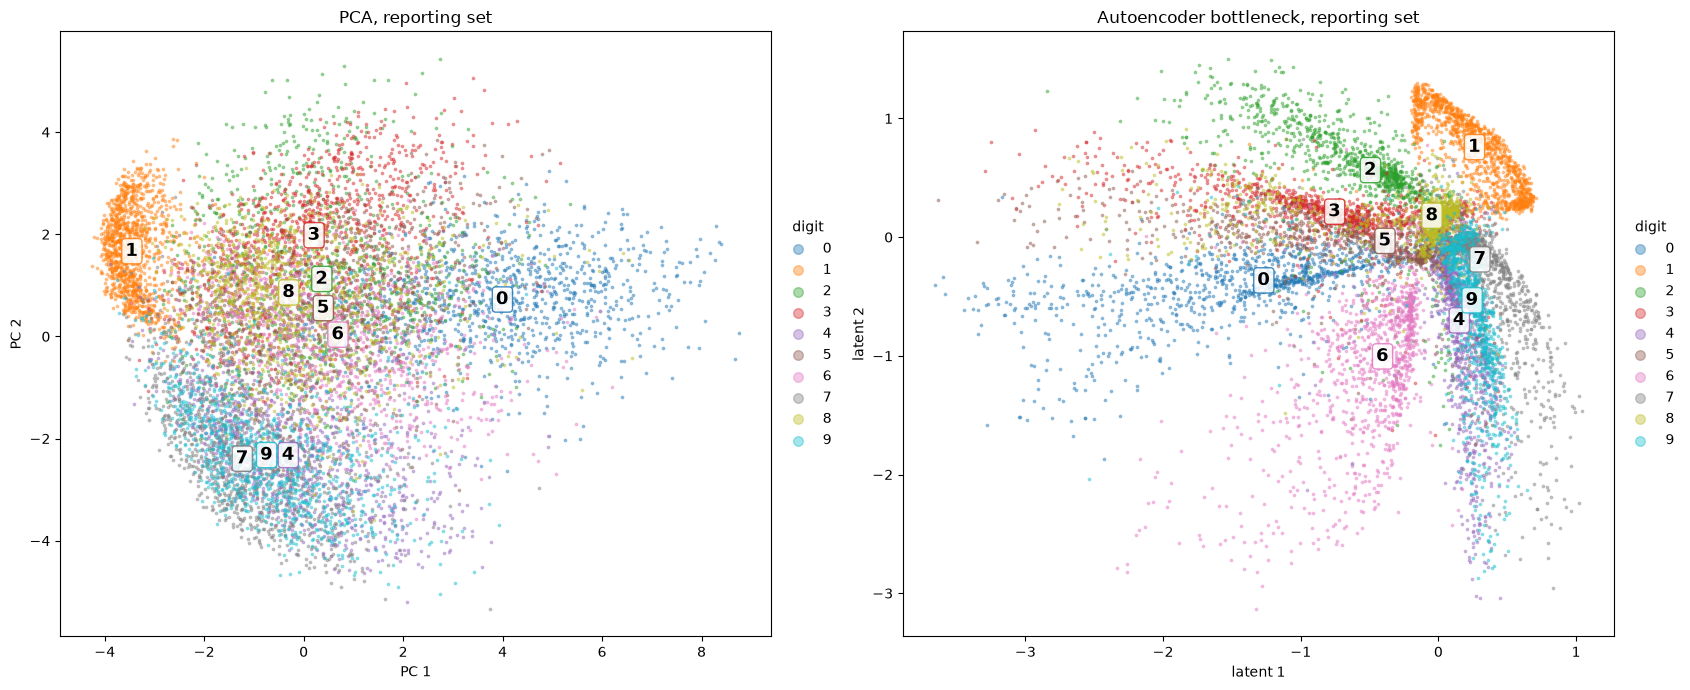

In [17]:
from sklearn.decomposition import PCA

# learn the 2 components on the fitting and tuning sets, then only transform the reporting set
X_rest_pca = np.vstack([X_fit, X_tune])
pca = PCA(n_components=2, random_state=42).fit(X_rest_pca)
latents_pca = pca.transform(X_report)

print(f"PCA features: {latents_pca.shape}")
print(f"Variance explained by the 2 components: {pca.explained_variance_ratio_.round(4)}, total {pca.explained_variance_ratio_.sum():.2%}")

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
plot_2d(latents_pca, y_report, "PCA, reporting set", axes[0], ("PC 1", "PC 2"))
plot_2d(latents_autoencoder, labels, "Autoencoder bottleneck, reporting set", axes[1], ("latent 1", "latent 2"))
plt.tight_layout()
plt.show()

In [18]:
from sklearn.neighbors import KNeighborsClassifier

# put numbers on the comparison
# 1. reconstruction error of each 2d representation on the reporting set
recon_pca = pca.inverse_transform(latents_pca)
mse_pca = ((recon_pca - X_report) ** 2).mean()
print(f"Reconstruction MSE per pixel, PCA:         {mse_pca:.5f}")
print(f"Reconstruction MSE per pixel, autoencoder: {mse_per_image.mean():.5f}")

# 2. how well digits are separated, measured by a kNN classifier that is fit on the 2d fitting set codes
#    and scored on the 2d reporting set codes. Labels are only used here, never to learn the 2d spaces
latents_fit_ae, labels_fit = extract_latent_features(model, fitting_loader)
latents_fit_pca = pca.transform(X_fit)

knn_ae = KNeighborsClassifier(n_neighbors=15).fit(latents_fit_ae, labels_fit)
knn_pca = KNeighborsClassifier(n_neighbors=15).fit(latents_fit_pca, y_fit)
print(f"\n15-NN digit accuracy in 2d, PCA:         {knn_pca.score(latents_pca, y_report):.2%}")
print(f"15-NN digit accuracy in 2d, autoencoder: {knn_ae.score(latents_autoencoder, labels):.2%}")

Reconstruction MSE per pixel, PCA:         0.05583
Reconstruction MSE per pixel, autoencoder: 0.04181



15-NN digit accuracy in 2d, PCA:         44.26%
15-NN digit accuracy in 2d, autoencoder: 74.38%


**Autoencoder vs PCA.**

The two plots look very different. In the PCA plot most digits pile up in one large overlapping cloud. The first component mostly separates digits with a lot of ink in a round shape, like 0, from thin digits like 1, and the rest of the classes sit on top of each other in the middle. The two components only explain a small share of the pixel variance, printed above, and PCA picks the directions of largest variance, which are not the directions that separate digits. In the autoencoder plot the same reporting images form distinct groups for most digits, and only similar looking digits like 4, 7 and 9 or 3, 5 and 8 still share space.

The numbers above back this up. With the same two dimensions the autoencoder has a lower reconstruction error than PCA, and a simple nearest neighbour classifier recognizes digits far more accurately from the autoencoder features than from the PCA features. The reason is that PCA can only use a flat linear projection of the pixels, while the encoder and decoder are nonlinear and can bend the space so that images of the same digit end up close together. This is the difference we predicted in Section 1.

PCA still has advantages. Its components are ordered by how much variance they explain, they are orthogonal, the result is the same every time, and it takes seconds to fit. The autoencoder axes have no fixed meaning, the map changes with the random seed, and training takes much longer and needs choices like the architecture, dropout and learning rate.

## 6. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

Sections 3, 4 and 5 all depend on the trained autoencoder, so they could not really be split between us the way the collaboration note suggests. The reconstruction plots, the latent space and the PCA comparison all had to wait until the model class and the training loop were finished and working, which pushed most of the work onto whoever went last and left less time to check the discussion against the results. For the next lab, we will agree on the shared pieces first, the data loaders, the model class and the trained weights, push them early and save the weights to a file with `torch.save`, so each of us can load the same model and write our own section in parallel instead of waiting in line.